# Talverin ReelPulse: Personalized Movie Recommendation Engine using Collaborative Filtering
**Persevex Artificial Intelligence Internship Project**

This notebook implements the complete 4-phase **Talverin ReelPulse** workflow:
1. **Phase 1: Data Analysis & The Utility Matrix** — MovieLens dataset (`Users`, `Movies`, `Ratings`), Long-Tail distribution & rating distribution EDA, User-Item Utility Matrix construction, and Sparsity Ratio calculation.
2. **Phase 2: Memory-Based Collaborative Filtering** — Manual implementation of **Cosine Similarity** in NumPy for both **User-User** and **Item-Item** Collaborative Filtering.
3. **Phase 3: Model-Based Collaborative Filtering (Matrix Factorization / SVD)** — Compressing the sparse Utility Matrix into User Embeddings ($P$) and Item Embeddings ($Q$) via Singular Value Decomposition (SVD), tuning latent factors $k$, and interpreting the 2D Latent Feature Space.
4. **Phase 4: Evaluation, Top-N Generator & Cold-Start Hybridization** — Comparing RMSE and Precision@K across User-Based, Item-Based, and SVD models, and running `recommendmovies(userid)`.

## Phase 1: Data Analysis, Exploratory Data Analysis (EDA) & The Utility Matrix

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, os.path.abspath('src'))
from cinematch_engine import (
    compute_cosine_similarity_matrix,
    MemoryBasedCF,
    SurpriseSVDModel,
    evaluate_rmse,
    evaluate_precision_at_k,
    recommendmovies as engine_recommendmovies
)

sns.set_theme(style='whitegrid')
%matplotlib inline

users_df = pd.read_csv('data/users.csv')
movies_df = pd.read_csv('data/movies.csv')
ratings_df = pd.read_csv('data/ratings.csv')

print(f'Users Table Shape:   {users_df.shape}')
print(f'Movies Table Shape:  {movies_df.shape}')
print(f'Ratings Table Shape: {ratings_df.shape}')
display(ratings_df.merge(movies_df, on='movieId').head(8))

Users Table Shape:   (400, 5)
Movies Table Shape:  (350, 3)
Ratings Table Shape: (10321, 4)


,userId,movieId,rating,timestamp,title,genres
0,1,127,2.5,1700000227,The Golden Labyrinth (1998),Action|Adventure|Sci-Fi
1,1,3,5.0,1700000103,The Lion King (1994),Animation|Children|Drama
2,1,100,4.0,1700000200,The Velvet Odyssey (2009),Comedy
3,1,51,4.0,1700000151,The Grand Budapest Hotel (2014),Comedy|Drama
4,1,5,4.5,1700000105,Finding Nemo (2003),Animation|Adventure|Children|Comedy
5,1,30,3.0,1700000130,Fight Club (1999),Action|Crime|Drama|Thriller
6,1,54,4.5,1700000154,Dumb and Dumber (1994),Comedy
7,1,61,4.0,1700000161,The Broken Fable (2008),Animation|Children|Comedy


In [2]:
# Build the User-Item Utility Matrix (Rows = Users, Columns = Movies)
utility_df = ratings_df.pivot(index='userId', columns='movieId', values='rating')
utility_df = utility_df.reindex(index=users_df['userId'], columns=movies_df['movieId'])

total_cells = utility_df.shape[0] * utility_df.shape[1]
observed_cells = ratings_df.shape[0]
empty_cells = total_cells - observed_cells
sparsity_ratio = (empty_cells / total_cells) * 100

print(f'Utility Matrix Dimensions: {utility_df.shape[0]} Users x {utility_df.shape[1]} Movies = {total_cells:,} cells')
print(f'Observed Ratings:          {observed_cells:,}')
print(f'Empty (NaN) Cells:         {empty_cells:,}')
print(f'Sparsity Ratio:            {sparsity_ratio:.2f}% empty')

Utility Matrix Dimensions: 400 Users x 350 Movies = 140,000 cells
Observed Ratings:          10,321
Empty (NaN) Cells:         129,679
Sparsity Ratio:            92.63% empty


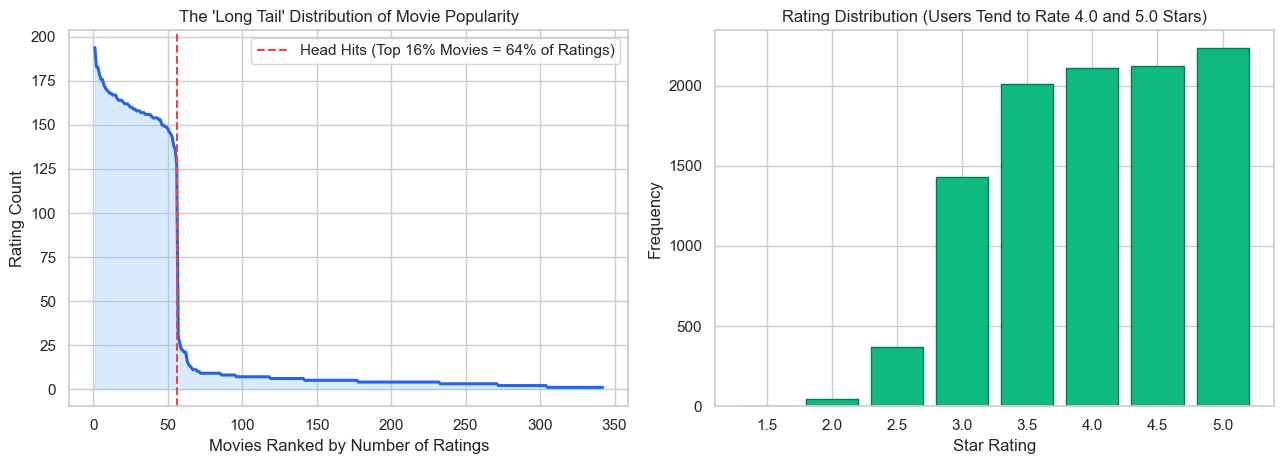

In [3]:
# EDA: Plot the 'Long Tail' Distribution of Movie Popularity & Rating Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

movie_counts = ratings_df.groupby('movieId').size().sort_values(ascending=False).values
ax1.plot(np.arange(1, len(movie_counts) + 1), movie_counts, color='#2563eb', linewidth=2.2)
ax1.fill_between(np.arange(1, len(movie_counts) + 1), movie_counts, color='#93c5fd', alpha=0.35)
ax1.axvline(56, color='#ef4444', linestyle='--', label='Head Hits (Top 16% Movies = 64% of Ratings)')
ax1.set_title("The 'Long Tail' Distribution of Movie Popularity")
ax1.set_xlabel('Movies Ranked by Number of Ratings')
ax1.set_ylabel('Rating Count')
ax1.legend()

rating_counts = ratings_df['rating'].value_counts().sort_index()
ax2.bar(rating_counts.index.astype(str), rating_counts.values, color='#10b981', edgecolor='#047857')
ax2.set_title('Rating Distribution (Users Tend to Rate 4.0 and 5.0 Stars)')
ax2.set_xlabel('Star Rating')
ax2.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

## Phase 2: Memory-Based Collaborative Filtering (Manual NumPy Cosine Similarity)
We manually implement **Cosine Similarity** between vectors $\mathbf{u}$ and $\mathbf{v}$ using NumPy:
$$\text{CosineSimilarity}(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\|_2 \, \|\mathbf{v}\|_2}$$

In [4]:
def manual_numpy_cosine_similarity(vec_a: np.ndarray, vec_b: np.ndarray) -> float:
    """Manual implementation of Cosine Similarity between two 1D vectors using NumPy."""
    mask = (~np.isnan(vec_a)) & (~np.isnan(vec_b))
    if np.sum(mask) == 0:
        return 0.0
    a, b = vec_a[mask], vec_b[mask]
    denom = (np.linalg.norm(a) * np.linalg.norm(b))
    return float(np.dot(a, b) / denom) if denom > 0 else 0.0

# Fit User-User and Item-Item Collaborative Filtering models on the Utility Matrix
user_cf_full = MemoryBasedCF(mode='user', k_neighbors=25).fit(utility_df)
item_cf_full = MemoryBasedCF(mode='item', k_neighbors=25).fit(utility_df)

# Item-Item Demo: 'Alice liked Star Wars; find movies that are similar to Star Wars based on other users ratings.'
star_wars_recs = item_cf_full.get_similar_movies('Star Wars: Episode IV', movies_df, top_n=5)
print("Item-Item CF: Movies most similar to 'Star Wars: Episode IV - A New Hope (1977)':")
display(pd.DataFrame(star_wars_recs))

Item-Item CF: Movies most similar to 'Star Wars: Episode IV - A New Hope (1977)':


/Users/shoumikaggarwal/Library/Mobile Documents/com~apple~CloudDocs/Persevex_Internship/Project2_Talverin ReelPulse_Recommender/src/cinematch_engine.py:311: RuntimeWarning: Mean of empty slice
  self.item_means = np.nanmean(self.R, axis=0)


,movieId,title,genres,cosine_similarity
0,16,The Matrix (1999),Action|Sci-Fi|Thriller,0.5030
1,24,Jurassic Park (1993),Action|Adventure|Sci-Fi,0.5000
2,20,Blade Runner (1982),Action|Sci-Fi|Thriller,0.4854
3,21,Aliens (1986),Action|Horror|Sci-Fi,0.4769
4,17,Inception (2010),Action|Sci-Fi|Thriller,0.4705


## Phase 3: Model-Based Collaborative Filtering (Matrix Factorization / SVD)
We factorize the sparse Utility Matrix $R$ into dense **User Embeddings ($P$)** and **Item Embeddings ($Q$)** with user/item biases:
$$\hat{r}_{u,i} = \mu + b_u + b_i + P_u \cdot Q_i^T$$

In [5]:
# Stratified 80/20 Train-Test Split per user
train_rows, test_rows = [], []
for uid, group in ratings_df.groupby('userId'):
    if uid == 101:
        train_rows.append(group)
        continue
    shuffled = group.sample(frac=1.0, random_state=42)
    n_test = max(2, int(len(shuffled) * 0.20))
    test_rows.append(shuffled.iloc[:n_test])
    train_rows.append(shuffled.iloc[n_test:])

train_df = pd.concat(train_rows, ignore_index=True)
test_df = pd.concat(test_rows, ignore_index=True)
train_utility_df = train_df.pivot(index='userId', columns='movieId', values='rating').reindex(
    index=users_df['userId'], columns=movies_df['movieId']
)

# Tune number of latent factors k in SVD
k_candidates = [5, 10, 20, 35, 50]
tuning_results = []
best_k, best_rmse, best_svd_model = 5, 999.0, None
for k in k_candidates:
    svd_k = SurpriseSVDModel(n_factors=k, n_epochs=35, lr=0.012, reg=0.04, random_state=42)
    svd_k.fit(train_df, all_user_ids=users_df['userId'], all_movie_ids=movies_df['movieId'])
    rmse_k = evaluate_rmse(svd_k, test_df)
    tuning_results.append({'k_factors': k, 'test_rmse': round(rmse_k, 4)})
    if rmse_k < best_rmse:
        best_rmse, best_k, best_svd_model = rmse_k, k, svd_k

print(f'Optimal SVD Latent Factors: k = {best_k} (Test RMSE = {best_rmse:.4f})')
display(pd.DataFrame(tuning_results))

Optimal SVD Latent Factors: k = 5 (Test RMSE = 0.3387)


,k_factors,test_rmse
0,5,0.3387
1,10,0.3544
2,20,0.3837
3,35,0.4206
4,50,0.4402


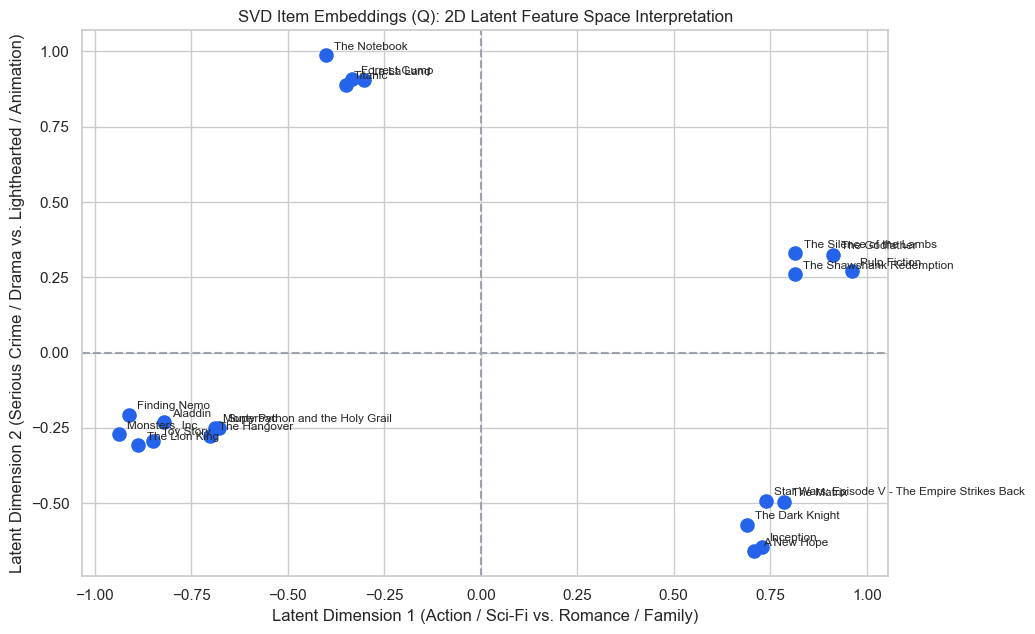

In [6]:
# Explore and Visualize the 2D Latent Features (Item Embeddings Q)
full_svd = SurpriseSVDModel(n_factors=best_k, n_epochs=40, lr=0.012, reg=0.04, random_state=42)
full_svd.fit(ratings_df, all_user_ids=users_df['userId'], all_movie_ids=movies_df['movieId'])

fig, ax = plt.subplots(figsize=(10.5, 6.5))
showcase_ids = [1, 2, 3, 5, 6, 13, 14, 16, 17, 22, 25, 26, 28, 32, 37, 38, 39, 45, 47, 48, 50]
for mid in showcase_ids:
    row = movies_df[movies_df['movieId'] == mid].iloc[0]
    m_idx = full_svd.movie_to_idx[mid]
    x_val, y_val = float(full_svd.Q[m_idx, 0]), float(full_svd.Q[m_idx, 1])
    ax.scatter(x_val, y_val, s=90, color='#2563eb')
    short_title = row['title'].split(' (')[0].replace('Star Wars: Episode IV - ', '')
    ax.annotate(short_title, (x_val, y_val), xytext=(6, 4), textcoords='offset points', fontsize=8.5)

ax.axhline(0, color='#9ca3af', linestyle='--')
ax.axvline(0, color='#9ca3af', linestyle='--')
ax.set_title('SVD Item Embeddings (Q): 2D Latent Feature Space Interpretation')
ax.set_xlabel('Latent Dimension 1 (Action / Sci-Fi vs. Romance / Family)')
ax.set_ylabel('Latent Dimension 2 (Serious Crime / Drama vs. Lighthearted / Animation)')
plt.tight_layout()
plt.show()

## Phase 4: Evaluation (RMSE & Precision@K) and `recommendmovies(userid)`

In [7]:
user_cf_train = MemoryBasedCF(mode='user', k_neighbors=25).fit(train_utility_df)
item_cf_train = MemoryBasedCF(mode='item', k_neighbors=25).fit(train_utility_df)

all_mids = list(movies_df['movieId'].values)
eval_rows = []
for name, model_obj in [
    ('User-Based Collaborative Filtering (Cosine)', user_cf_train),
    ('Item-Based Collaborative Filtering (Cosine)', item_cf_train),
    (f'Matrix Factorization - SVD (k={best_k})', best_svd_model)
]:
    eval_rows.append({
        'Model': name,
        'Test RMSE': round(evaluate_rmse(model_obj, test_df), 4),
        'Precision@5': round(evaluate_precision_at_k(model_obj, train_df, test_df, all_mids, k=5), 4),
        'Precision@10': round(evaluate_precision_at_k(model_obj, train_df, test_df, all_mids, k=10), 4)
    })

eval_df = pd.DataFrame(eval_rows)
display(eval_df)

/Users/shoumikaggarwal/Library/Mobile Documents/com~apple~CloudDocs/Persevex_Internship/Project2_Talverin ReelPulse_Recommender/src/cinematch_engine.py:311: RuntimeWarning: Mean of empty slice
  self.item_means = np.nanmean(self.R, axis=0)


,Model,Test RMSE,Precision@5,Precision@10
0,User-Based Collaborative Filtering (Cosine),0.3752,0.4595,0.4401
1,Item-Based Collaborative Filtering (Cosine),0.3820,0.0350,0.0514
2,Matrix Factorization - SVD (k=5),0.3387,0.5985,0.5720


In [8]:
def recommendmovies(userid: int, top_n: int = 5):
    """Prints and returns the top-5 suggested titles for the given user profile."""
    recs = engine_recommendmovies(userid, full_svd, movies_df, ratings_df, top_n=top_n)
    liked = ratings_df[(ratings_df['userId'] == userid) & (ratings_df['rating'] >= 4.0)].merge(movies_df, on='movieId')
    fav_str = ', '.join(liked['title'].head(3).tolist()) if not liked.empty else 'New User (Cold Start)'
    print(f'For User #{userid} (who likes {fav_str}), we recommend:')
    for r in recs:
        print(f"  #{r['rank']}: {r['title']} ({r['genres']}) -> Predicted Rating: {r['predicted_rating']:.2f} ★")
    return pd.DataFrame(recs)

# Deliverable 3 Showcase: User #101 (who likes Toy Story)
df_user101 = recommendmovies(101)

For User #101 (who likes Toy Story (1995), Toy Story 2 (1999), Shrek (2001)), we recommend:
  #1: The Lion King (1994) (Animation|Children|Drama) -> Predicted Rating: 4.57 ★
  #2: Monsters, Inc. (2001) (Animation|Children|Comedy) -> Predicted Rating: 4.54 ★
  #3: Finding Nemo (2003) (Animation|Adventure|Children|Comedy) -> Predicted Rating: 4.49 ★
  #4: Aladdin (1992) (Animation|Children|Musical) -> Predicted Rating: 4.39 ★
  #5: Ferris Bueller's Day Off (1986) (Comedy) -> Predicted Rating: 4.24 ★
